# Tome S3, Chapter 6: Collatz (Python companion)

Exercises first, solutions at the end. We measure the walks of the Collatz map up to $10^7$, test the coin model of Theorem 5.4 by brute
force, compute Terras's densities exactly, grow the backward tree, reproduce the cycle bounds of Corollary 5.11, and run Conway's
PRIMEGAME. We use `numpy`, `mpmath` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math, time
from fractions import Fraction
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt
T = lambda n: n // 2 if n % 2 == 0 else (3 * n + 1) // 2

## Exercises

**P6.1 (★) Long walks.** For every $n\le10^7$ compute the number of steps of $C$ needed to reach $1$. List the records, find the mean, and compare it
with the heuristic $10.43\log n$ of the chapter.

**P6.2 (★) The coin model.** For $k\le16$, check by brute force that $n\bmod 2^k\mapsto v_k(n)$ is a bijection (Theorem 5.4), and that the
number of odd steps is binomially distributed (Corollary 5.5).

**P6.3 (★★) Terras's densities.** Compute exactly, for $k\le60$, the proportion of residues modulo $2^k$ whose parity vector has not stopped by step $k$
(Figure 5.3). Compare it with the proportion of $n\le2^{22}$ whose stopping time $\sigma(n)$ is larger than $k$.

**P6.4 (★★) The backward tree.** Grow the backward tree of $1$ (Figure 5.2) to depth $60$. How fast do the levels grow? A first guess is
$\frac43$: every $m$ has the predecessor $2m$, and about one even number in three is $\equiv4\pmod 6$ (Exercise 5.3). Is the guess right? If
not, find a better model by keeping track of each node modulo $6$.

**P6.5 (★★) Cycles are long.** Run the Stern–Brocot descent of Theorem 5.10 with exact fractions for $M=2^{40}$, $2^{68}$ and $2^{71}$.

**P6.6 (★) PRIMEGAME.** Write a FRACTRAN interpreter (Remark 5.5) and run Conway's PRIMEGAME from $2$. Print the powers of $2$ that appear and
the number of steps needed for each.

## Solutions

### P6.1
**How to find it.** Memoise: walk from $n$ until you reach a number already computed, then fill in the walk backwards. Numbers above $10^7$ are not stored.

records: [(626331, 508), (837799, 524), (1117065, 527), (1501353, 530), (1723519, 556), (2298025, 559), (3064033, 562), (3542887, 583), (3732423, 596), (5649499, 612), (6649279, 664), (8400511, 685)]


mean steps for n <= 10^7: 155.27   mean of 10.43 log n: 157.65   (17 s)


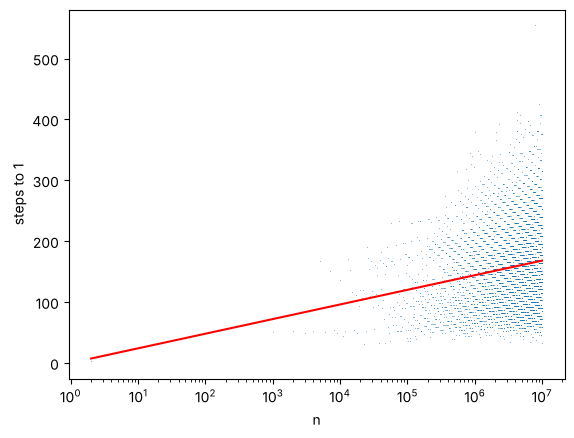

In [2]:
t0 = time.time()
N = 10**7
steps = np.zeros(N + 1, dtype=np.int32)
for n in range(2, N + 1):
    m, path = n, []
    while m > N or (m != 1 and steps[m] == 0):
        path.append(m); m = m // 2 if m % 2 == 0 else 3 * m + 1
    d = int(steps[m])
    for x in reversed(path):
        d += 1
        if x <= N: steps[x] = d
rec, best = [], -1
for n in range(1, N + 1):
    if steps[n] > best: best = steps[n]; rec.append((n, int(best)))
print('records:', rec[-12:])
ns = np.arange(2, N + 1)
print('mean steps for n <= 10^7: %.2f   mean of 10.43 log n: %.2f   (%.0f s)' % (steps[2:].mean(), (3 / math.log(4 / 3) * np.log(ns)).mean(), time.time() - t0))
plt.plot(ns[::997], steps[2::997], ',', alpha=0.5); plt.plot(ns[::997], 3 / math.log(4 / 3) * np.log(ns[::997]), 'r')
plt.xscale('log'); plt.xlabel('n'); plt.ylabel('steps to 1'); plt.show()

The record up to $10^7$ is $8\,400\,511$ with $685$ steps, and the mean is close to the heuristic (a little below, as for $10^6$ in the chapter: the
heuristic ignores the "$+1$", and the end of the walk, near $1$, is not random). The cloud of points has a sharp lower edge, the powers of $2$ and
their neighbours, and a long upper tail made of the long climbers.

### P6.2
**How to find it.** Compute $v_k(n)$ for $n=1,\dots,2^k$ and count distinct vectors.

In [3]:
def pvec(n, k):
    v = []
    for _ in range(k):
        v.append(n & 1); n = T(n)
    return tuple(v)
for k in (4, 8, 12, 16):
    vs = [pvec(n, k) for n in range(1, 2**k + 1)]
    counts = np.bincount([sum(v) for v in vs], minlength=k + 1)
    print(k, 'distinct vectors:', len(set(vs)), 'of', 2**k, '  binomial:', all(counts[s] == math.comb(k, s) for s in range(k + 1)))

4 distinct vectors: 16 of 16   binomial: True
8 distinct vectors: 256 of 256   binomial: True
12 distinct vectors: 4096 of 4096   binomial: True
16 distinct vectors: 65536 of 65536   binomial: True


All $2^k$ vectors appear, each once, and the number of odd steps follows $\binom ks$ exactly. This is the precise sense in which the first $k$ steps
are fair coin tosses.

### P6.3
**How to find it.** A dynamic programme over the number $s$ of odd steps: keep only the vectors with $3^{s_j}\ge2^j$ at every step $j$. For the
empirical side, compute $\sigma(n)$ directly.

In [4]:
dp, frac = {0: 1}, []
for j in range(1, 61):
    nd = {}
    for s, c in dp.items():
        for b in (0, 1):
            if 3 ** (s + b) >= 2 ** j: nd[s + b] = nd.get(s + b, 0) + c
    dp = nd; frac.append(sum(dp.values()) / 2 ** j)
def sigma(n):
    m, k = n, 0
    while True:
        m = T(m); k += 1
        if m < n: return k
K = 2**22
sig = np.array([sigma(n) for n in range(2, K + 1)])
for k in (5, 10, 20, 30, 40, 60):
    print('k=%2d  exact %.6f   empirical (n <= 2^22) %.6f   Chernoff %.4f' % (k, frac[k - 1], np.mean(sig > k), math.exp(-0.034688 * k)))
print('largest stopping time below 2^22:', sig.max(), 'at n =', 2 + sig.argmax())

k= 5  exact 0.125000   empirical (n <= 2^22) 0.125000   Chernoff 0.8408
k=10  exact 0.062500   empirical (n <= 2^22) 0.062500   Chernoff 0.7069
k=20  exact 0.026062   empirical (n <= 2^22) 0.026062   Chernoff 0.4997
k=30  exact 0.011894   empirical (n <= 2^22) 0.011890   Chernoff 0.3532
k=40  exact 0.005823   empirical (n <= 2^22) 0.005704   Chernoff 0.2497
k=60  exact 0.001922   empirical (n <= 2^22) 0.001878   Chernoff 0.1248
largest stopping time below 2^22: 224 at n = 1126015


The exact and empirical proportions agree exactly for $k\le20$, as they must: $2^{22}$ consecutive numbers contain each residue modulo $2^k$ equally
often, and a residue class that has stopped by step $k$ contains only stopped numbers, except a few small ones below the bound $B_k$ of the proof of
Theorem 5.7. For $k=30$ to $60$ the agreement is still good, though no longer exact: $2^{22}$ numbers see only a sample of the residues
modulo $2^k$. The largest stopping time below $2^{22}$ is $224$, at $1\,126\,015$. The Chernoff bound is true but far from sharp at this range.

### P6.4
**How to find it.** Level $d+1$ consists of $2m$ for every $m$ in level $d$, and $\frac{m-1}3$ when $m\equiv4\pmod 6$ (and $m\neq4$).

In [5]:
level, sizes = [1], [1]
seen = {1}
for d in range(60):
    nxt = []
    for m in level:
        for p in [2 * m] + ([(m - 1) // 3] if m % 6 == 4 and m > 4 else []):
            if p not in seen: seen.add(p); nxt.append(p)
    level = nxt; sizes.append(len(level))
print(sizes[:25])
print('ratios at depth 40..60:', [round(sizes[d + 1] / sizes[d], 3) for d in range(40, 60, 4)])
print('ratio over the last 20 levels, per level: %.4f' % (sizes[60] / sizes[40]) ** (1 / 20))

[1, 1, 1, 1, 1, 2, 2, 4, 4, 6, 6, 8, 10, 14, 18, 24, 29, 36, 44, 58, 72, 91, 113, 143, 179]
ratios at depth 40..60: [1.263, 1.263, 1.264, 1.264, 1.264]
ratio over the last 20 levels, per level: 1.2637


The levels grow geometrically, but with ratio $1.2637$, not $\frac43$. The first guess forgets two things. An odd node is never $\equiv4\pmod 6$, so a
new odd branch must double once before it can branch again; and a branch that starts at a multiple of $3$ is a dead end, a chain of doublings
(Exercise 5.3). Sort the nodes not divisible by $3$ into four types: even and $\equiv1$ or $\equiv2\pmod3$ ($E_1$, $E_2$), odd and $\equiv1$
or $\equiv2\pmod 3$ ($O_1$, $O_2$). Doubling swaps the residues $1$ and $2$ modulo $3$ and makes the node even, so
$E_1\to E_2$, $E_2\to E_1$, $O_1\to E_2$, $O_2\to E_1$; and an $E_1$ node (that is, $m\equiv4\pmod 6$) also gets an odd child whose residue modulo $3$ is
$0$, $1$ or $2$ with frequency $\frac13$ each. If the counts grow like $\lambda^d$, then $\lambda E_1=E_2+O_2$, $\lambda E_2=E_1+O_1$ and
$\lambda O_1=\lambda O_2=\frac{E_1}3$, which gives $3\lambda^3-4\lambda-1=0$, that is $(\lambda+1)(3\lambda^2-3\lambda-1)=0$, and
$\lambda=\frac{3+\sqrt{21}}6=1.26376$. The computed ratio agrees to four digits.

### P6.5
**How to find it.** `mpmath` with $80$ digits gives $\log_23$ far more precisely than the $10^{-22}$ we need; the descent itself uses integers.

In [6]:
mp.mp.dps = 80
alpha = mp.log(3) / mp.log(2)
for e in (40, 68, 71):
    M = mp.mpf(2) ** e
    delta = 1 / (3 * M * mp.log(2))
    p, q, P, Q = 1, 1, 2, 1
    while True:
        a, b = p + P, q + Q
        if mp.mpf(a) / b < alpha: p, q = a, b
        elif mp.mpf(a) / b >= alpha + delta: P, Q = a, b
        else: break
    assert P * q - p * Q == 1
    s = q + Q; k = int(mp.ceil(s * alpha))
    print('M = 2^%d: left %d/%d, right %d/%d;  s >= %d, k >= %d, C-length k + s >= %d' % (e, p, q, P, Q, s, k, k + s))

M = 2^40: left 16785921/10590737, right 301994/190537;  s >= 10781274, k >= 17087915, C-length k + s >= 27869189
M = 2^68: left 103768467013/65470613321, right 10439860591/6586818670;  s >= 72057431991, k >= 114208327604, C-length k + s >= 186265759595
M = 2^71: left 103768467013/65470613321, right 10439860591/6586818670;  s >= 72057431991, k >= 114208327604, C-length k + s >= 186265759595


For $M=2^{40}$ the bound is $k\ge17\,087\,915$, Eliahou's number of 1993, and the right end $\frac{301\,994}{190\,537}$ also appears in his paper. For
$M=2^{68}$ and $M=2^{71}$ the descent stops at the same pair, because no fraction with denominator between $6.6\cdot10^9$ and $7.2\cdot10^{10}$ comes
closer to $\log_23$: the bound only improves when $M$ crosses the next threshold.

### P6.6
**How to find it.** Store the program as `Fraction`s; at each step try them in order.

In [7]:
PRIMEGAME = [Fraction(a, b) for a, b in [(17, 91), (78, 85), (19, 51), (23, 38), (29, 33), (77, 29), (95, 23), (77, 19), (1, 17), (11, 13), (13, 11), (15, 2), (1, 7), (55, 1)]]
def fractran(prog, n):
    while True:
        for f in prog:
            m = n * f
            if m.denominator == 1:
                n = m.numerator; yield n; break
        else:
            return
found = []
for step, n in enumerate(fractran(PRIMEGAME, 2), 1):
    if n & (n - 1) == 0:
        found.append((n.bit_length() - 1, step))
        if len(found) == 10: break
print(found)

[(2, 19), (3, 69), (5, 281), (7, 710), (11, 2375), (13, 3893), (17, 8102), (19, 11361), (23, 19268), (29, 36981)]


The exponents are $2,3,5,7,11,13,17,19,23,29$, the primes in order, after $19$, $69$, $281$, $710$, ... steps. The cost grows fast: PRIMEGAME tests every
candidate by repeated subtraction. Each step multiplies $n$ by a fraction chosen according to $n$ modulo $\mathrm{lcm}(91,85,51,38,33,29,23,19,17,13,11,2,7)$,
so PRIMEGAME is a map of exactly the type of Conway's theorem.